<a href="https://colab.research.google.com/github/itsasimiqbal/SeBRe/blob/master/SeBRe_2_0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#`SeBRe 2.0` 🐁
```
Asim Iqbal, et al. "Developing a brain atlas through deep learning." Nature Machine Intelligence 1.6 (2019): 277-287.
Developed with 💙 in 🏔 Zürich, CH and 🌃 Seattle, WA
```
[Paper link](https://rdcu.be/b4DfW) | [GitHub link](https://github.com/itsasimiqbal/SeBRe) | [Online link](https://www.nature.com/articles/s42256-019-0058-8)

![picture](https://github.com/itsasimiqbal/SeBRe/raw/master/SeBRe_block_diagram.png)
![picture](https://miro.medium.com/max/4000/0*VbMjGBHMC6GnDKUp.png)

### `import libraries`
```
⤴ from Runtime (top-left) ➡ Change runtime type ➡ Hardware accelerator ➡ Select GPU
this may take a few minutes to install :wait
```

In [1]:
!pip install pyyaml==5.1
import torch
TORCH_VERSION = ".".join(torch.__version__.split(".")[:2])
CUDA_VERSION = torch.__version__.split("+")[-1]
print("torch: ", TORCH_VERSION, "; cuda: ", CUDA_VERSION)
print('Available # of GPUs:', torch.cuda.device_count())
print('GPU type:', torch.cuda.get_device_name())
!python -m pip install 'git+https://github.com/facebookresearch/detectron2.git'
!pip install -U --no-cache-dir gdown --pre
# exit(0)  # After installation, you may need to "restart runtime" in Colab. This line can also restart runtime

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 274.2/274.2 kB 9.0 MB/s eta 0:00:00
  error: subprocess-exited-with-error
  
  × python setup.py egg_info did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Preparing metadata (setup.py) ... error
error: metadata-generation-failed

× Encountered error while generating package metadata.
╰─> See above for output.

note: This is an issue with the package mentioned above, not pip.
hint: See above for details.
torch:  2.6 ; cuda:  cu124
Available # of GPUs: 1
GPU type: Tesla T4
  Cloning https://github.com/facebookresearch/detectron2.git to /tmp/pip-req-build-qfdj1uru
  Running command git clone --filter=blob:none --quiet https://github.com/facebookresearch/detectron2.git /tmp/pip-req-build-qfdj1uru
  Resolved https://github.com/facebookresearch/detectron2.git to commit 18f69583391e5040043ca4f4bebd2c60f0ebfde0
  Preparing metadata (setu

In [2]:
import detectron2
# import some common detectron2 utilities
from detectron2 import model_zoo
from detectron2.engine import DefaultPredictor
from detectron2.config import get_cfg
from detectron2.utils.visualizer import Visualizer
from detectron2.data import MetadataCatalog, DatasetCatalog
from detectron2.utils.logger import setup_logger
setup_logger()
from detectron2.structures import BoxMode
from pycocotools.mask import encode
from detectron2 import model_zoo

# import some common libraries
import numpy as np
import os, json, cv2, random
from google.colab.patches import cv2_imshow
import matplotlib.pyplot as plt
import numpy as np
import cv2
import math
import time
import glob
import random
import os
!pip install wget
import wget
import tarfile
from google.colab.patches import cv2_imshow

# Mount data directly from Google drive - uncomment these lines to load data from Gdrive
# from google.colab import drive
# drive.mount('/content/drive')

  Preparing metadata (setup.py) ... done
  Created wheel for wget: filename=wget-3.2-py3-none-any.whl size=9655 sha256=cd6fd377faea98e6f0f77e8d58419b935c2c94f0777a4be1068f46f5626c28b4
  Stored in directory: /root/.cache/pip/wheels/40/b3/0f/a40dbd1c6861731779f62cc4babcb234387e11d697df70ee97
Successfully built wget


### `Cloning repo & downloading sample mouse_dataset`

In [3]:
!git clone https://github.com/itsasimiqbal/SeBRe.git
my_tar = tarfile.open('/content/SeBRe/mouse_dataset.tgz')
my_tar.extractall()
my_tar.close()

Cloning into 'SeBRe'...
remote: Enumerating objects: 260, done.
remote: Counting objects: 100% (29/29), done.
remote: Compressing objects: 100% (28/28), done.
remote: Total 260 (delta 9), reused 4 (delta 1), pack-reused 231 (from 1)
Receiving objects: 100% (260/260), 91.99 MiB | 20.31 MiB/s, done.
Resolving deltas: 100% (119/119), done.


### `loading mouse_dataset`

In [4]:
# change these paths to your local/Gdrive
path = '/content/mouse_dataset/'
output_directory = '/content/SeBre_2.0/Checkpoint/'
folder  = 'train'
number = 0 # sample to count labels
images_list = glob.glob(path + f'{folder}/Gray/*.png')#f'images/{folder}/*.png')
print('total no. of images: ', len(images_list))
masks_list = sorted(glob.glob(path + f'{folder}/masks2{folder}/*_{number}.png'))
print('total no. of masks/image: ', len(masks_list))

total no. of images:  280
total no. of masks/image:  7


In [5]:
dataset_dicts = []

def get_custom_dataset(path, folder='train'):
  dataset_dicts = []
  images_list = glob.glob(path + f'{folder}/Gray/*.png')

  for idx, fname in enumerate(images_list):
      record = {}
      number = fname.split('/')[-1].split('.')[0]
      height, width = cv2.imread(fname).shape[:2]
      record['file_name'] =  fname
      record['image_id'] = idx
      record['height'] = height
      record['width'] = width
      masks_list = sorted(glob.glob(path + f'{folder}/masks2{folder}/*_{number}.png'))
      objs = []
      for jdx, mname in enumerate(masks_list):

          mask = cv2.imread(mname)[:,:,0]
          if np.max(mask) == 255:
              mask = mask / 255
          mask = mask.astype(np.uint8)
          formated_mask = encode(np.asarray(mask, order="F"))

          px = np.sum(mask, axis=0) != 0
          py = np.sum(mask, axis=1) != 0

          obj = {
              "bbox": [np.argmax(px), np.argmax(py), len(px) - np.argmax(px[::-1]), len(py) - np.argmax(py[::-1])],
              "bbox_mode": BoxMode.XYXY_ABS,
              "segmentation": formated_mask,
              "category_id": jdx,
          }
          objs.append(obj)
      record['annotations'] = objs
      dataset_dicts.append(record)
      print('processing: ', idx+1, '/', len(images_list),' sample')
  return dataset_dicts


for d in ["train", "val"]:
    DatasetCatalog.register("mousenew_" + d, lambda d=d: get_custom_dataset(path, d))
    MetadataCatalog.get("mousenew_" + d).set(thing_classes=['cortex', 'hippocampus', 'thalamus','hypothalamus', 'telen_vesicle', 'mid_brain', 'hind_brain'])#change these to your class labels
mouse_metadata = MetadataCatalog.get("mousenew_train")

In [6]:
MetadataCatalog['mousenew_train']

namespace(name='mousenew_train',
          thing_classes=['cortex',
                         'hippocampus',
                         'thalamus',
                         'hypothalamus',
                         'telen_vesicle',
                         'mid_brain',
                         'hind_brain'])

In [7]:
dataset_dicts = get_custom_dataset(path, 'train')

processing:  1 / 280  sample
processing:  2 / 280  sample
processing:  3 / 280  sample
processing:  4 / 280  sample
processing:  5 / 280  sample
processing:  6 / 280  sample
processing:  7 / 280  sample
processing:  8 / 280  sample
processing:  9 / 280  sample
processing:  10 / 280  sample
processing:  11 / 280  sample
processing:  12 / 280  sample
processing:  13 / 280  sample
processing:  14 / 280  sample
processing:  15 / 280  sample
processing:  16 / 280  sample
processing:  17 / 280  sample
processing:  18 / 280  sample
processing:  19 / 280  sample
processing:  20 / 280  sample
processing:  21 / 280  sample
processing:  22 / 280  sample
processing:  23 / 280  sample
processing:  24 / 280  sample
processing:  25 / 280  sample
processing:  26 / 280  sample
processing:  27 / 280  sample
processing:  28 / 280  sample
processing:  29 / 280  sample
processing:  30 / 280  sample
processing:  31 / 280  sample
processing:  32 / 280  sample
processing:  33 / 280  sample
processing:  34 / 2

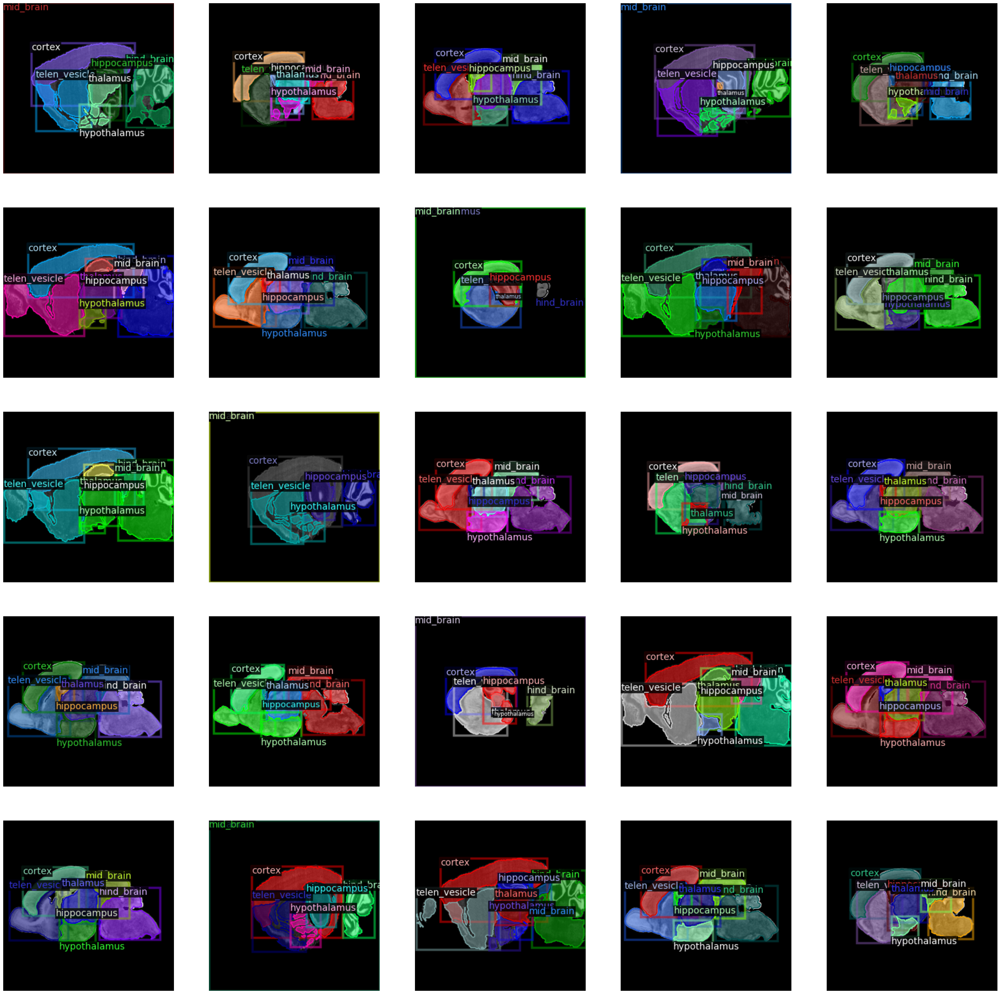

In [8]:
plt.figure(figsize=(40,40));
x=0
for d in random.sample(dataset_dicts, 25):
    img = cv2.imread(d["file_name"])
    visualizer = Visualizer(img[:, :, ::-1], metadata=mouse_metadata, scale=1)
    out = visualizer.draw_dataset_dict(d)
    plt.subplot(5,5,x+1)
    plt.imshow(out.get_image()[:, :, ::-1]); plt.axis('off')
    x+=1

### `Inference`
`testing a pre-trained model -  trained on 5000 iters`

In [9]:
import gdown
import tarfile
# downloading weights
url = "https://drive.google.com/file/d/1mnfJLyz7xj97LmcZkAPvLaAan-pF4iJP/view?usp=sharing"
output = "SeBRe_2.0_max_iter_5000.tar"
gdown.download(url=url, output=output, quiet=False, fuzzy=True)

my_tar = tarfile.open('/content/SeBRe_2.0_max_iter_5000.tar')
my_tar.extractall()
my_tar.close()

from detectron2.engine import DefaultPredictor, DefaultTrainer
from detectron2.config import get_cfg
cfg = get_cfg()
cfg.merge_from_file(model_zoo.get_config_file("COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml"))
cfg.DATASETS.TRAIN = ("mousenew_train",)
cfg.DATASETS.TEST = ()
cfg.DATALOADER.NUM_WORKERS = 2
cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url("COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml")  # Let training initialize from model zoo
cfg.SOLVER.IMS_PER_BATCH = 2
cfg.SOLVER.BASE_LR = 0.00025  # pick a good LR
cfg.SOLVER.MAX_ITER = 1000    # 1000 iterations seems good enough for this toy dataset; you will need to train longer for a practical dataset
cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE = 512   # faster, and good enough for this toy dataset (default: 512)
cfg.MODEL.ROI_HEADS.NUM_CLASSES = 7  # change it for the max number of classes for custom dataset
cfg.CHECKPOINT_PERIOD = 100 # save checkpoint after every 100th iteration
cfg.OUTPUT_DIR = '/content/SeBRe_2.0_max_iter_5000/Checkpoint'

cfg.MODEL.WEIGHTS = os.path.join(cfg.OUTPUT_DIR, "model_final.pth")  # path to the model we just trained
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.5   # set a custom testing threshold
predictor = DefaultPredictor(cfg)

Downloading...
From (original): https://drive.google.com/uc?id=1mnfJLyz7xj97LmcZkAPvLaAan-pF4iJP
From (redirected): https://drive.google.com/uc?id=1mnfJLyz7xj97LmcZkAPvLaAan-pF4iJP&confirm=t&uuid=baf8e945-2598-4c81-ad63-51ccef3e1fc8
To: /content/SeBRe_2.0_max_iter_5000.tar
100%|██████████| 328M/328M [00:09<00:00, 35.8MB/s]


[08/09 17:06:46 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/SeBRe_2.0_max_iter_5000/Checkpoint/model_final.pth ...


In [10]:
# preparing test data
dataset_dicts_test = get_custom_dataset(path, 'test')

processing:  1 / 140  sample
processing:  2 / 140  sample
processing:  3 / 140  sample
processing:  4 / 140  sample
processing:  5 / 140  sample
processing:  6 / 140  sample
processing:  7 / 140  sample
processing:  8 / 140  sample
processing:  9 / 140  sample
processing:  10 / 140  sample
processing:  11 / 140  sample
processing:  12 / 140  sample
processing:  13 / 140  sample
processing:  14 / 140  sample
processing:  15 / 140  sample
processing:  16 / 140  sample
processing:  17 / 140  sample
processing:  18 / 140  sample
processing:  19 / 140  sample
processing:  20 / 140  sample
processing:  21 / 140  sample
processing:  22 / 140  sample
processing:  23 / 140  sample
processing:  24 / 140  sample
processing:  25 / 140  sample
processing:  26 / 140  sample
processing:  27 / 140  sample
processing:  28 / 140  sample
processing:  29 / 140  sample
processing:  30 / 140  sample
processing:  31 / 140  sample
processing:  32 / 140  sample
processing:  33 / 140  sample
processing:  34 / 1

/usr/local/lib/python3.11/dist-packages/torch/functional.py:539: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:3637.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


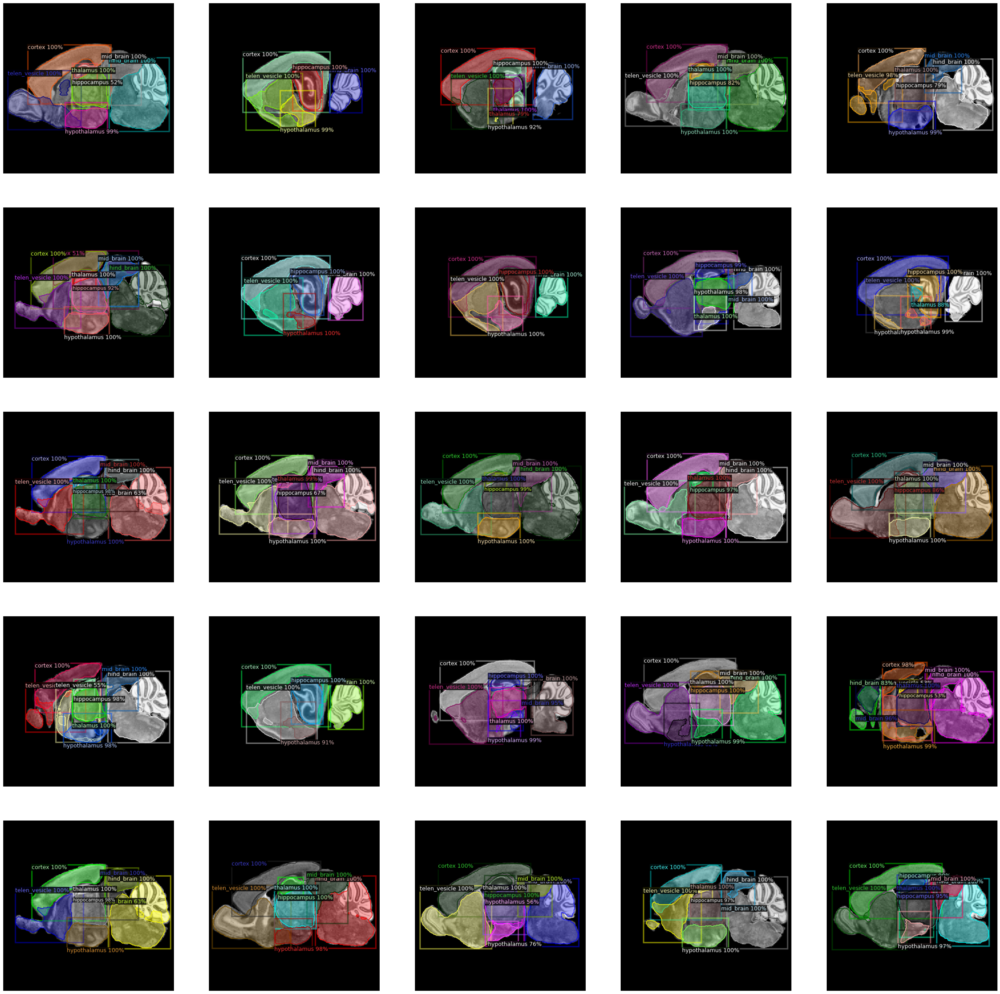

In [11]:
# visualizing results
grid = 5 #int(math.ceil(np.sqrt(np.shape(dataset_dicts_test)[0])))
from detectron2.utils.visualizer import ColorMode
plt.figure(figsize=(40,40))
x=0
for d in random.sample(dataset_dicts_test, 25):
    im = cv2.imread(d["file_name"])
    outputs = predictor(im)
    v = Visualizer(im[:, :, ::-1],
                   metadata=mouse_metadata,
                   scale=1.5,
                   instance_mode=ColorMode.IMAGE_BW
    )
    out = v.draw_instance_predictions(outputs["instances"].to("cpu"))
    plt.subplot(grid,grid,x+1)
    plt.imshow(out.get_image()[:, :, ::-1]); plt.axis('off')
    x+=1

### `Training (fine-tuning)`
```
*   loading a pre-trained model from model_zoo and finetune on mouse dataset
*   this may take some ⏰, grab a cup of ☕
```

In [12]:
from detectron2.engine import DefaultPredictor, DefaultTrainer
cfg = get_cfg()
cfg.merge_from_file(model_zoo.get_config_file("COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml"))
cfg.DATASETS.TRAIN = ("mousenew_train",)
cfg.DATASETS.TEST = ()
cfg.DATALOADER.NUM_WORKERS = 2
cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url("COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml")  # Let training initialize from model zoo
cfg.SOLVER.IMS_PER_BATCH = 2
cfg.SOLVER.BASE_LR = 0.00025  # pick a good LR
cfg.SOLVER.MAX_ITER = 1000    # 1000 iterations seems good enough for this toy dataset; you will need to train longer for a practical dataset
cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE = 512   # faster, and good enough for this toy dataset (default: 512)
cfg.MODEL.ROI_HEADS.NUM_CLASSES = 7  # change it for the max number of classes for custom dataset
cfg.CHECKPOINT_PERIOD = 100 # save checkpoint after every 100th iteration
cfg.OUTPUT_DIR = output_directory
if not os.path.exists(output_directory):
  os.makedirs(output_directory)
cfg.INPUT.MASK_FORMAT = 'bitmask'
os.makedirs(cfg.OUTPUT_DIR, exist_ok=True)
trainer = DefaultTrainer(cfg)
trainer.resume_or_load(resume=False)
trainer.train()

cfg.MODEL.WEIGHTS = os.path.join(cfg.OUTPUT_DIR, "model_final.pth")  # path to the model we just trained
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.5   # set a custom testing threshold
predictor = DefaultPredictor(cfg)

[08/09 17:07:28 d2.engine.defaults]: Model:
GeneralizedRCNN(
  (backbone): FPN(
    (fpn_lateral2): Conv2d(256, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral3): Conv2d(512, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output3): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral4): Conv2d(1024, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output4): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral5): Conv2d(2048, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output5): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (top_block): LastLevelMaxPool()
    (bottom_up): ResNet(
      (stem): BasicStem(
        (conv1): Conv2d(
          3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False
          (norm): FrozenBatchNorm2d(num_features=64, eps=1e-05)
        )
      )
      (res

model_final_f10217.pkl: 178MB [00:03, 51.8MB/s]                           
roi_heads.box_predictor.bbox_pred.{bias, weight}
roi_heads.box_predictor.cls_score.{bias, weight}
roi_heads.mask_head.predictor.{bias, weight}


[08/09 17:07:36 d2.engine.train_loop]: Starting training from iteration 0


/usr/local/lib/python3.11/dist-packages/detectron2/data/detection_utils.py:449: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:203.)
  torch.stack([torch.from_numpy(np.ascontiguousarray(x)) for x in masks])
/usr/local/lib/python3.11/dist-packages/detectron2/data/detection_utils.py:449: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program

[08/09 17:07:46 d2.utils.events]:  eta: 0:06:55  iter: 19  total_loss: 3.813  loss_cls: 2.106  loss_box_reg: 0.5322  loss_mask: 0.6923  loss_rpn_cls: 0.4036  loss_rpn_loc: 0.06547    time: 0.4227  last_time: 0.4390  data_time: 0.0194  last_data_time: 0.0117   lr: 4.9953e-06  max_mem: 2726M
[08/09 17:08:03 d2.utils.events]:  eta: 0:06:49  iter: 39  total_loss: 3.601  loss_cls: 1.912  loss_box_reg: 0.5476  loss_mask: 0.691  loss_rpn_cls: 0.3877  loss_rpn_loc: 0.05406    time: 0.4520  last_time: 0.4665  data_time: 0.0148  last_data_time: 0.0063   lr: 9.9902e-06  max_mem: 2843M
[08/09 17:08:12 d2.utils.events]:  eta: 0:06:47  iter: 59  total_loss: 3.208  loss_cls: 1.584  loss_box_reg: 0.6024  loss_mask: 0.6891  loss_rpn_cls: 0.2428  loss_rpn_loc: 0.05081    time: 0.4484  last_time: 0.4808  data_time: 0.0105  last_data_time: 0.0078   lr: 1.4985e-05  max_mem: 2920M
[08/09 17:08:21 d2.utils.events]:  eta: 0:06:43  iter: 79  total_loss: 2.834  loss_cls: 1.227  loss_box_reg: 0.6522  loss_mask: 

### `Inference on custom-trained model`
`Observe the difference b/w results of previous (max_iter=5000) and this (max_iter=1000) model - previous one is better due to more training`

`Tip: Re-run the training for 5000+ epochs to achieve better results` 🐁

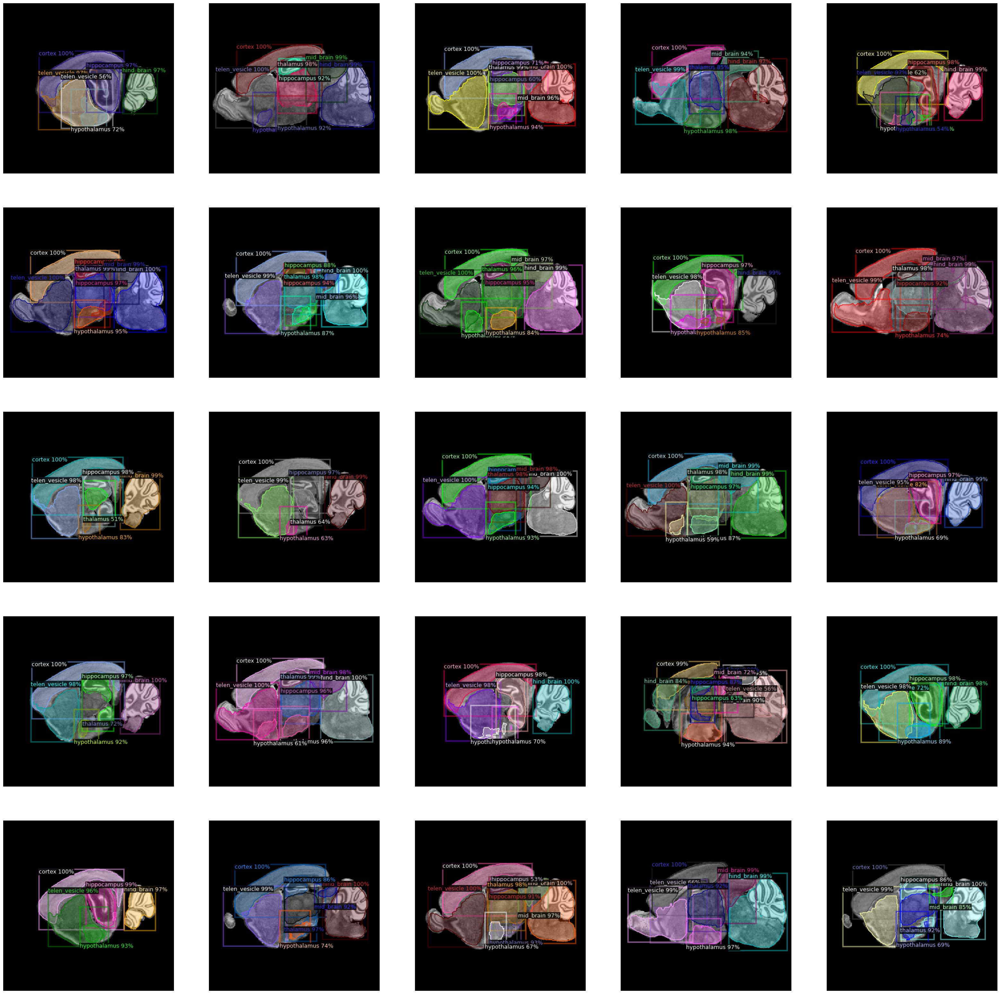

In [13]:
grid = 5 #int(math.ceil(np.sqrt(np.shape(dataset_dicts_test)[0])))
from detectron2.utils.visualizer import ColorMode
plt.figure(figsize=(40,40))
x=0
for d in random.sample(dataset_dicts_test, 25):
    im = cv2.imread(d["file_name"])
    outputs = predictor(im)
    v = Visualizer(im[:, :, ::-1],
                   metadata=mouse_metadata,
                   scale=1.5,
                   instance_mode=ColorMode.IMAGE_BW
    )
    out = v.draw_instance_predictions(outputs["instances"].to("cpu"))
    plt.subplot(grid,grid,x+1)
    plt.imshow(out.get_image()[:, :, ::-1]); plt.axis('off')
    x+=1

`inference time`

In [14]:
times = []
for i in range(20):
    start_time = time.time()
    outputs = predictor(im)
    delta = time.time() - start_time
    times.append(delta)
mean_delta = np.array(times).mean()
fps = 1 / mean_delta
print("Average(sec):{:.2f},fps:{:.2f}".format(mean_delta, fps))

Average(sec):0.12,fps:8.47
